# Práctico: comparar detectores sobre un servicio más difícil (estudiantes)

Las clases 9–11 cubrieron cuatro familias de detectores. Acá las enfrentamos **al mismo dataset**, más cargado que el plano $(N_t,R_t)$ de las clases 10 y 11.

$$
\text{logs}\longrightarrow\text{ventanas}\longrightarrow\mathbf x_t
\longrightarrow s(\mathbf x_t)\longrightarrow h_\tau(\mathbf x_t).
$$

## Detectores

| Método | Vista | Pregunta |
|---|---|---|
| k-sigma (z-score) | univariado | ¿$x$ está a más de $k$ desvíos de $\mu$? |
| MAD (z-score robusto) | univariado | ¿$x$ está lejos de la mediana, con escala $1.4826\,\mathrm{MAD}$? |
| Isolation Forest | multivariado | ¿$x$ se aísla rápido con cortes aleatorios? |
| One-Class SVM (RBF) | multivariado | ¿$x$ queda fuera de la frontera del volumen normal? |

## Lo que cambia respecto de las clases 10 y 11

El servicio sigue siendo el mismo tipo de historia (requests, errores, ahora también latencia y CPU). La nube normal sigue siendo un **manifold**: las cuatro métricas se mueven juntas con la carga. Encima hay:

1. anomalías fáciles (un eje se dispara);
2. combinaciones raras (ningún eje es extremo, el *par* o el *cuádruple* sí);
3. trampas operativas (pico de carga y un job batch que son **legítimos**);
4. una degradación lenta y tres spikes de error rate (duelen al k-sigma, menos al MAD).

`kind` e `is_anomaly` están para **evaluar después**. No los usen para entrenar.


## Cómo trabajar este cuaderno

1. Ejecuten todo hasta el final de la sección 3 (datos + exploración + protocolo).
2. Completen los `TODO` de las secciones 4 a 7. Cada una pide un *score* y una *flag*.
3. Recién ahí corran la comparación. Si una bandera no existe, esa sección va a fallar.
4. Respondan las preguntas del cierre con evidencia de las tablas y los gráficos, no de memoria.

Nombres de columnas que el cuaderno espera:

- `flag_ksigma_error`, `flag_ksigma_lat`
- `flag_mad_error`, `flag_mad_lat`
- `flag_if`, `flag_ocsvm`


In [1]:
from __future__ import annotations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.ensemble import IsolationForest
from sklearn.metrics import precision_recall_fscore_support
from sklearn.preprocessing import StandardScaler
from sklearn.svm import OneClassSVM

SEED = 42
rng = np.random.default_rng(SEED)

plt.style.use("seaborn-v0_8-whitegrid")
BLUE, ORANGE, GREEN, GRAY, PURPLE, TEAL = "#183B66", "#E76F51", "#2A9D8F", "#5F6B76", "#8E5BA6", "#00A6A6"
plt.rcParams["figure.figsize"] = (9, 4.6)
plt.rcParams["axes.titlesize"] = 12

KIND_COLORS = {
    "normal": BLUE,
    "batch": TEAL,
    "pico_carga": GREEN,
    "spike_error": "#C9A227",
    "incidente_5xx": ORANGE,
    "timeouts": PURPLE,
    "latencia_silenciosa": "#D62828",
    "combo_sutil": "#9B2226",
    "degradacion": "#BC6C25",
    "cpu_latencia": "#6A4C93",
    "micro_burst": "#F4A261",
}

print(f"Semilla: {SEED}")


Semilla: 42


## 1. Dataset sintético

Cada fila es **un minuto** de un servicio de checkout. Features:

- $N_t$ `requests` — volumen,
- $R_t$ `error_rate` — fracción de ERROR,
- `latency_ms` — latencia media de la ventana,
- `cpu_pct` — CPU del pod.

La relación normal es aproximadamente lineal con la carga. Lo raro no es “un número grande”: es **salirse de esa relación**, o un eje que se rompe mientras los otros no.


In [2]:
minutes = pd.date_range("2026-06-03 08:00", periods=300, freq="min")
n = len(minutes)
hour = minutes.hour.to_numpy() + minutes.minute.to_numpy() / 60.0
# Misma familia de trafico que clases 10-11: rampa matinal, no un salto de regimen.
traffic = 70 + 90 * np.clip(np.sin((hour - 8) * np.pi / 6), 0, None)
requests = np.maximum(25, np.rint(traffic + rng.normal(0, 8, n))).astype(float)
error_rate = np.clip(0.0035 + 0.000045 * requests + rng.normal(0, 0.0010, n), 0.0008, None)
latency_ms = np.clip(68 + 0.22 * requests + rng.normal(0, 6.5, n), 40, None)
cpu_pct = np.clip(16 + 0.17 * requests + rng.normal(0, 4.0, n), 8, None)

kind = np.full(n, "normal", dtype=object)


def window(start, end):
    return np.asarray((minutes >= start) & (minutes < end))


# Job batch legitimo: CPU alto, el resto sigue el manifold. NO es incidente.
for start in ("2026-06-03 08:25", "2026-06-03 09:12", "2026-06-03 10:30", "2026-06-03 11:42"):
    m = window(start, pd.Timestamp(start) + pd.Timedelta(minutes=5))
    kind[m] = "batch"
    cpu_pct[m] = rng.uniform(70, 84, m.sum())
    requests[m] = np.maximum(25, requests[m] - rng.integers(8, 14, m.sum()))
    error_rate[m] = np.clip(0.0035 + 0.000045 * requests[m] + rng.normal(0, 0.0008, m.sum()), 0.0008, None)
    latency_ms[m] = np.clip(68 + 0.22 * requests[m] + rng.normal(0, 5.0, m.sum()), 40, None)

# Spikes univariados de error_rate: contaminan media y sigma, casi no mueven al MAD.
for ts in ("2026-06-03 08:18", "2026-06-03 08:41", "2026-06-03 09:05"):
    m = window(ts, pd.Timestamp(ts) + pd.Timedelta(minutes=1))
    kind[m] = "spike_error"
    error_rate[m] = rng.uniform(0.021, 0.025, m.sum())

# Incidente clasico (combinacion rara): poco trafico, mucho error, latencia alta.
m = window("2026-06-03 09:50", "2026-06-03 09:58")
kind[m] = "incidente_5xx"
requests[m] = rng.integers(30, 44, m.sum())
error_rate[m] = rng.uniform(0.036, 0.048, m.sum())
latency_ms[m] = rng.uniform(210, 260, m.sum())
cpu_pct[m] = rng.uniform(28, 40, m.sum())

# Timeouts: trafico medio, error y latencia altos.
m = window("2026-06-03 09:22", "2026-06-03 09:26")
kind[m] = "timeouts"
error_rate[m] = rng.uniform(0.023, 0.028, m.sum())
latency_ms[m] = rng.uniform(175, 200, m.sum())

# Pico de carga sobre el manifold: extremo en un eje, relacion habitual.
m = window("2026-06-03 11:18", "2026-06-03 11:26")
kind[m] = "pico_carga"
requests[m] = rng.integers(165, 185, m.sum())
error_rate[m] = 0.0035 + 0.000045 * requests[m] + rng.normal(0, 0.0007, m.sum())
latency_ms[m] = 68 + 0.22 * requests[m] + rng.normal(0, 5.0, m.sum())
cpu_pct[m] = 16 + 0.17 * requests[m] + rng.normal(0, 3.5, m.sum())

# Latencia silenciosa: solo un eje se rompe.
m = window("2026-06-03 10:40", "2026-06-03 10:46")
kind[m] = "latencia_silenciosa"
latency_ms[m] = rng.uniform(195, 230, m.sum())

# Combinacion sutil: poco trafico + error alto, pero cada eje crudo queda bajo 3 MAD.
# Es un incidente_5xx atenuado: se ve en el plano, no en un histograma.
m = window("2026-06-03 10:08", "2026-06-03 10:15")
kind[m] = "combo_sutil"
requests[m] = rng.integers(50, 62, m.sum())
error_rate[m] = rng.uniform(0.0132, 0.0140, m.sum())
latency_ms[m] = rng.uniform(118, 128, m.sum())
cpu_pct[m] = 16 + 0.17 * requests[m] + rng.normal(0, 3.5, m.sum())

# Degradacion colectiva: la latencia sube de a poco. El primer minuto casi no se ve.
m = window("2026-06-03 11:50", "2026-06-03 12:08")
kind[m] = "degradacion"
ramp = np.linspace(8, 95, m.sum())
latency_ms[m] = latency_ms[m] + ramp

# Degradacion parcial: CPU y latencia, sin errores.
m = window("2026-06-03 12:22", "2026-06-03 12:27")
kind[m] = "cpu_latencia"
cpu_pct[m] = rng.uniform(78, 90, m.sum())
latency_ms[m] = rng.uniform(180, 215, m.sum())

# Micro-burst: facil para todos.
m = window("2026-06-03 12:41", "2026-06-03 12:43")
kind[m] = "micro_burst"
error_rate[m] = rng.uniform(0.055, 0.070, m.sum())
latency_ms[m] = rng.uniform(240, 280, m.sum())

anomalous_kinds = {
    "spike_error", "incidente_5xx", "timeouts", "latencia_silenciosa",
    "combo_sutil", "degradacion", "cpu_latencia", "micro_burst",
}
data = pd.DataFrame({
    "timestamp": minutes,
    "requests": requests,
    "error_rate": error_rate,
    "latency_ms": latency_ms,
    "cpu_pct": cpu_pct,
    "kind": kind,
})
data["is_anomaly"] = data["kind"].isin(anomalous_kinds)
FEATURES = ["requests", "error_rate", "latency_ms", "cpu_pct"]

print(f"Ventanas: {len(data)}  |  anomalías reales: {int(data.is_anomaly.sum())} ({100 * data.is_anomaly.mean():.1f}%)")
display(data.groupby("kind")[FEATURES].agg(["count", "mean"]).round(3))


Ventanas: 300  |  anomalías reales: 53 (17.7%)


requests          error_rate        latency_ms           \
                       count     mean      count   mean      count     mean   
kind                                                                          
batch                     20  121.750         20  0.009         20   92.201   
combo_sutil                7   54.571          7  0.014          7  122.551   
cpu_latencia               5  139.000          5  0.010          5  205.789   
degradacion               18  144.722         18  0.010         18  154.781   
incidente_5xx              8   36.750          8  0.042          8  235.876   
latencia_silenciosa        6  158.333          6  0.010          6  213.073   
micro_burst                2  123.500          2  0.063          2  277.415   
normal                   219  131.137        219  0.009        219   96.067   
pico_carga                 8  173.875          8  0.012          8  104.374   
spike_error                3  107.333          3  0.023          3   88.102   
timeouts                   4  127.250          4  0.025          4  191.117   

                    cpu_pct          
                      count    mean  
kind                                 
batch                    20  75.925  
combo_sutil               7  24.982  
cpu_latencia              5  86.313  
degradacion              18  40.230  
incidente_5xx             8  36.217  
latencia_silenciosa       6  43.764  
micro_burst               2  37.104  
normal                  219  38.424  
pico_carga                8  46.033  
spike_error               3  35.427  
timeouts                  4  39.604

## 2. Exploración

Primero las series. Después, tres planos. El pico de carga debería verse *al extremo de la nube*; el incidente_5xx, *afuera*; el batch, *arriba en CPU* con requests normales.


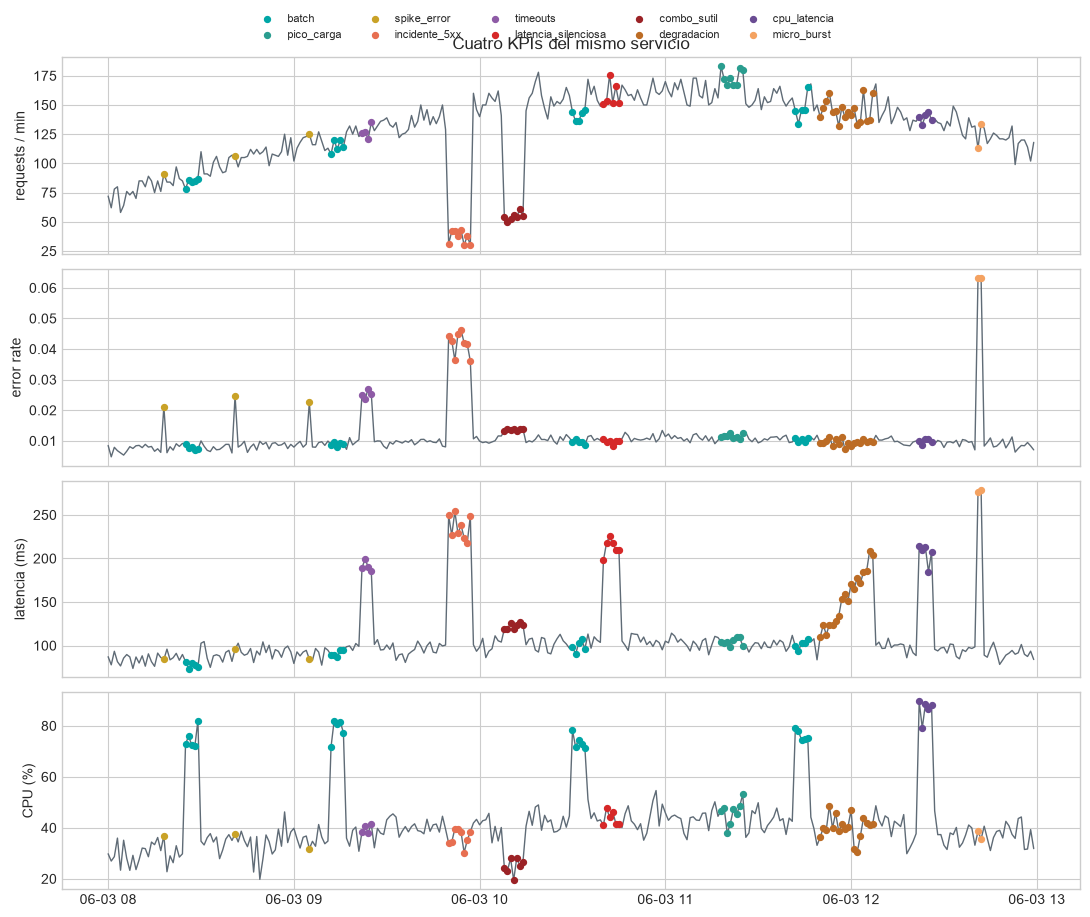

In [3]:
fig, axes = plt.subplots(4, 1, figsize=(11, 9), sharex=True)
series = [("requests", "requests / min"), ("error_rate", "error rate"), ("latency_ms", "latencia (ms)"), ("cpu_pct", "CPU (%)")]
for ax, (col, ylabel) in zip(axes, series):
    ax.plot(data["timestamp"], data[col], color=GRAY, lw=1.0)
    for name, color in KIND_COLORS.items():
        if name == "normal":
            continue
        mask = data["kind"].eq(name)
        ax.scatter(data.loc[mask, "timestamp"], data.loc[mask, col], c=color, s=18, zorder=3, label=name)
    ax.set_ylabel(ylabel)
axes[0].set_title("Cuatro KPIs del mismo servicio")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=5, bbox_to_anchor=(0.5, 1.02), fontsize=8)
plt.tight_layout()
plt.show()


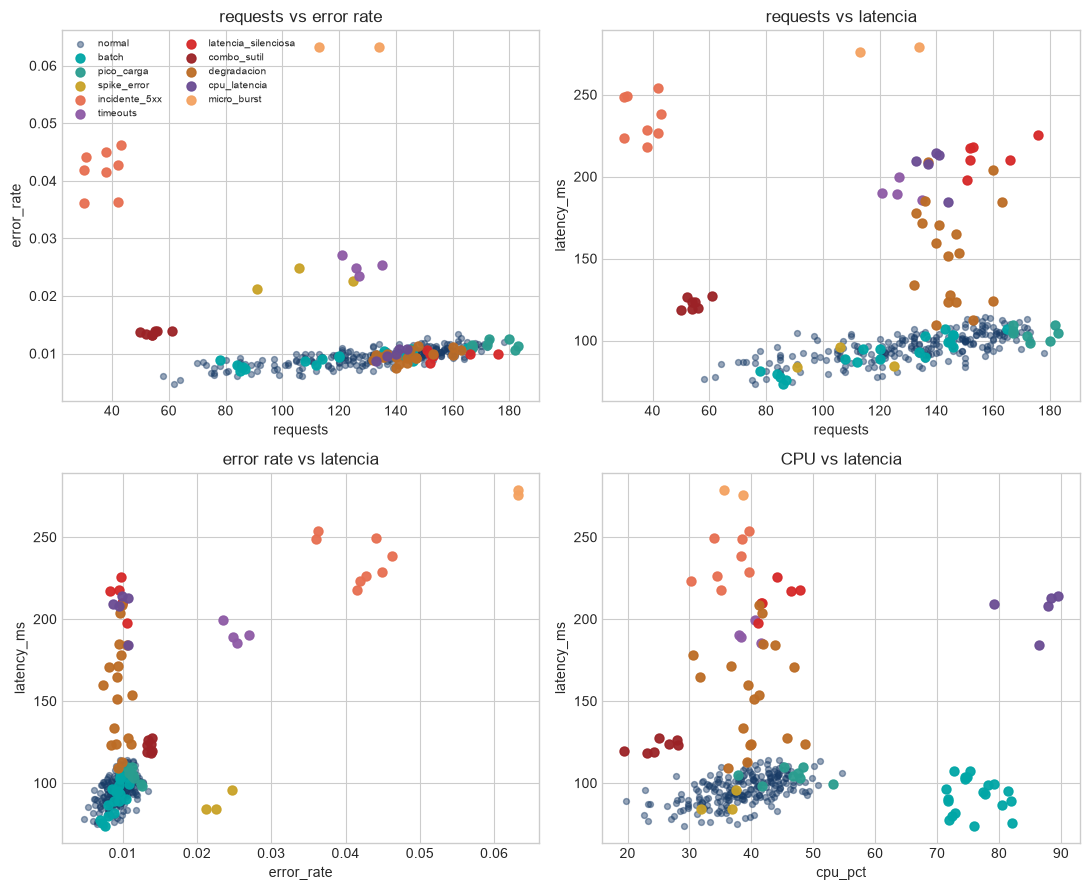

In [4]:
planes = [
    ("requests", "error_rate", "requests vs error rate"),
    ("requests", "latency_ms", "requests vs latencia"),
    ("error_rate", "latency_ms", "error rate vs latencia"),
    ("cpu_pct", "latency_ms", "CPU vs latencia"),
]
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for ax, (a, b, title) in zip(axes.ravel(), planes):
    for name, color in KIND_COLORS.items():
        mask = data["kind"].eq(name)
        ax.scatter(
            data.loc[mask, a], data.loc[mask, b],
            c=color, s=18 if name == "normal" else 42,
            alpha=0.45 if name == "normal" else 0.95,
            label=name, zorder=2 if name == "normal" else 3,
        )
    ax.set_xlabel(a)
    ax.set_ylabel(b)
    ax.set_title(title)
axes[0, 0].legend(loc="upper left", fontsize=7, ncol=2)
plt.tight_layout()
plt.show()


## 3. Protocolo de entrenamiento

Igual que Isolation Forest en la clase 10: **no hay etiquetas para aprender**. Estimamos todo sobre las 300 ventanas.

- Univariados: $\mu,\sigma$ y mediana/MAD se estiman sobre **toda** la serie. La muestra está contaminada (incidentes, spikes). Eso es el punto: k-sigma se deja llevar, MAD no.
- Isolation Forest y One-Class SVM se entrenan sobre las cuatro features **escaladas**, también sin `kind`.
- `contamination=0.10` y `nu=0.10` son un presupuesto de alertas (~30 minutos), no la tasa verdadera (~17%).
- `pico_carga` y `batch` están marcados como *no anómalos*: son trampas. Si un detector los enciende, es un falso positivo con historia operativa.


In [5]:
print("Minutos por kind:")
display(data["kind"].value_counts().rename("n").to_frame())

scaler = StandardScaler().fit(data[FEATURES])
X_all = scaler.transform(data[FEATURES])
print("Medias del scaler:", dict(zip(FEATURES, scaler.mean_.round(3))))
print("Escalas del scaler:", dict(zip(FEATURES, scaler.scale_.round(3))))


Minutos por kind:


,n
kind,
normal,219
batch,20
degradacion,18
incidente_5xx,8
pico_carga,8
combo_sutil,7
latencia_silenciosa,6
cpu_latencia,5
timeouts,4


Medias del scaler: {'requests': np.float64(128.497), 'error_rate': np.float64(0.011), 'latency_ms': np.float64(110.465), 'cpu_pct': np.float64(41.745)}
Escalas del scaler: {'requests': np.float64(32.487), 'error_rate': np.float64(0.007), 'latency_ms': np.float64(38.48), 'cpu_pct': np.float64(12.56)}


## 4. k-sigma (univariado)

Sobre una serie $x_1,\dots,x_n$ (acá, las 300 ventanas):

$$
\hat\mu=\bar x,\qquad
\hat\sigma=\sqrt{\frac1{n-1}\sum_i(x_i-\hat\mu)^2},\qquad
s_k(x)=\left|\frac{x-\hat\mu}{\hat\sigma}\right|.
$$

Alerta si $s_k(x)>k$. Usamos $k=3$. Aplíquenlo a `error_rate` y a `latency_ms`.

Ojo: los tres `spike_error` y los incidentes grandes están *dentro* de la muestra. Inflan $\hat\sigma$ del error rate. Eso es parte del ejercicio.


In [6]:
def k_sigma_fit(series: pd.Series):
    # Devuelve (mu, sigma) estimados sobre la serie, con ddof=1.
    mu = float(series.mean())
    sigma = float(series.std(ddof=1))
    return mu, sigma


def k_sigma_score(series: pd.Series, mu: float, sigma: float):
    # Score |x - mu| / sigma, alineado con el indice de series.
    return (series - mu).abs() / sigma


K = 3.0
mu_err, sig_err = k_sigma_fit(data["error_rate"])
mu_lat, sig_lat = k_sigma_fit(data["latency_ms"])
data["score_ksigma_error"] = k_sigma_score(data["error_rate"], mu_err, sig_err)
data["score_ksigma_lat"] = k_sigma_score(data["latency_ms"], mu_lat, sig_lat)
data["flag_ksigma_error"] = data["score_ksigma_error"] > K
data["flag_ksigma_lat"] = data["score_ksigma_lat"] > K

print(f"error_rate  μ={mu_err:.4f}  σ={sig_err:.4f}  umbral 3σ={mu_err + 3 * sig_err:.4f}")
print(f"latency_ms  μ={mu_lat:.2f}  σ={sig_lat:.2f}  umbral 3σ={mu_lat + 3 * sig_lat:.1f}")
print("Alertas k-sigma error:", int(data.flag_ksigma_error.sum()), "| latencia:", int(data.flag_ksigma_lat.sum()))


error_rate  μ=0.0112  σ=0.0072  umbral 3σ=0.0328
latency_ms  μ=110.47  σ=38.54  umbral 3σ=226.1
Alertas k-sigma error: 10 | latencia: 8


## 5. MAD / z-score robusto (univariado)

$$
\widetilde x=\operatorname{median}(x_i),\qquad
\operatorname{MAD}=\operatorname{median}(|x_i-\widetilde x|),\qquad
\widehat\sigma_{\mathrm{MAD}}=1.4826\,\operatorname{MAD}.
$$

$$
s_r(x)=\left|\frac{x-\widetilde x}{\widehat\sigma_{\mathrm{MAD}}}\right|.
$$

Alerta si $s_r(x)>k$, otra vez $k=3$. La constante $1.4826$ hace que, si $x$ fuera normal, $\widehat\sigma_{\mathrm{MAD}}$ estime $\sigma$. Mediana y MAD toleran hasta casi un $50\%$ de contaminación; los tres spikes no deberían desplazarlos.


In [7]:
def mad_fit(series: pd.Series):
    # Devuelve (mediana, MAD, escala=1.4826*MAD).
    med = float(series.median())
    mad = float((series - med).abs().median())
    return med, mad, 1.4826 * mad


def mad_score(series: pd.Series, med: float, scale: float):
    # Score |x - mediana| / escala. Si escala==0, devolver 0 en la mediana e inf fuera.
    if scale == 0:
        return pd.Series(np.where(series == med, 0.0, np.inf), index=series.index)
    return (series - med).abs() / scale


med_err, mad_err, scale_err = mad_fit(data["error_rate"])
med_lat, mad_lat, scale_lat = mad_fit(data["latency_ms"])
data["score_mad_error"] = mad_score(data["error_rate"], med_err, scale_err)
data["score_mad_lat"] = mad_score(data["latency_ms"], med_lat, scale_lat)
data["flag_mad_error"] = data["score_mad_error"] > K
data["flag_mad_lat"] = data["score_mad_lat"] > K

print(f"error_rate  mediana={med_err:.4f}  MAD={mad_err:.4f}  escala={scale_err:.4f}  (σ k-sigma={sig_err:.4f})")
print(f"latency_ms  mediana={med_lat:.2f}  MAD={mad_lat:.2f}  escala={scale_lat:.2f}  (σ k-sigma={sig_lat:.2f})")
print("Alertas MAD error:", int(data.flag_mad_error.sum()), "| latencia:", int(data.flag_mad_lat.sum()))


error_rate  mediana=0.0097  MAD=0.0010  escala=0.0016  (σ k-sigma=0.0072)
latency_ms  mediana=99.22  MAD=7.84  escala=11.62  (σ k-sigma=38.54)
Alertas MAD error: 18 | latencia: 36


## 6. Isolation Forest (multivariado, 4D)

Entrenen sobre `X_all` (300 ventanas ya escaladas). `contamination` es una **política** de recorte, no un diagnóstico: acá $0.10$.

Score para ranking, igual que en la clase 10:

$$
\mathrm{score}_{\mathrm{IF}}(x)=-\texttt{score\_samples}(x).
$$

Flag: `predict == -1`. Features: las cuatro.


In [8]:
forest = IsolationForest(
    n_estimators=300,
    max_samples=min(256, len(data)),
    contamination=0.10,
    random_state=42,
).fit(X_all)

data["score_if"] = -forest.score_samples(X_all)
data["flag_if"] = forest.predict(X_all) == -1
print("Alertas Isolation Forest:", int(data.flag_if.sum()))


Alertas Isolation Forest: 30


## 7. One-Class SVM RBF (multivariado, 4D)

Mismas 300 ventanas, mismas features escaladas. Kernel RBF, `nu=0.10`, `gamma="scale"`.

$$
f(x)=\sum_{i\in\mathrm{SV}}\alpha_i\,k(x_i,x)-\rho,\qquad
\mathrm{score}_{\mathrm{OCSVM}}(x)=-f(x).
$$

Flag: `predict == -1` (equivalente a $f(x)<0$).


In [9]:
ocsvm = OneClassSVM(kernel="rbf", nu=0.10, gamma="scale").fit(X_all)

data["score_ocsvm"] = -ocsvm.decision_function(X_all)
data["flag_ocsvm"] = ocsvm.predict(X_all) == -1
print("Alertas One-Class SVM:", int(data.flag_ocsvm.sum()))


Alertas One-Class SVM: 29


## 8. Comparación

Cada fila es un `kind`. Cada columna cuenta **minutos alertados**. Un detector univariado sobre error rate no tiene por qué ver `latencia_silenciosa`. Un detector 4D no tiene por qué perdonar el `combo_sutil`. `batch` y `pico_carga` son el test de falsos positivos.


In [10]:
FLAG_COLS = {
    "k-sigma error": "flag_ksigma_error",
    "k-sigma lat": "flag_ksigma_lat",
    "MAD error": "flag_mad_error",
    "MAD lat": "flag_mad_lat",
    "Isolation Forest": "flag_if",
    "One-Class SVM": "flag_ocsvm",
}

missing = [c for c in FLAG_COLS.values() if c not in data.columns]
if missing:
    raise RuntimeError(f"Faltan columnas {missing}. Completá las secciones 4-7 antes de comparar.")

counts = data.groupby("kind")[list(FLAG_COLS.values())].sum().astype(int)
counts.columns = list(FLAG_COLS)
counts["n"] = data.groupby("kind").size()
counts["anómalo?"] = data.groupby("kind")["is_anomaly"].any()
display(counts[["n", "anómalo?", *FLAG_COLS]])

score_cols = {
    "k-sigma error": "score_ksigma_error",
    "k-sigma lat": "score_ksigma_lat",
    "MAD error": "score_mad_error",
    "MAD lat": "score_mad_lat",
    "IF": "score_if",
    "OCSVM": "score_ocsvm",
}
print("Mediana del score por kind (el ranking, no la flag):")
display(data.groupby("kind")[list(score_cols.values())].median().round(3).rename(columns={v: k for k, v in score_cols.items()}))


,n,anómalo?,k-sigma error,k-sigma lat,MAD error,MAD lat,Isolation Forest,One-Class SVM
kind,,,,,,,,
batch,20,False,0,0,0,0,4,5
combo_sutil,7,True,0,0,0,0,4,1
cpu_latencia,5,True,0,0,0,5,5,3
degradacion,18,True,0,0,0,11,0,1
incidente_5xx,8,True,8,6,8,8,8,4
latencia_silenciosa,6,True,0,0,0,6,1,3
micro_burst,2,True,2,2,2,2,2,2
normal,219,False,0,0,1,0,2,4
pico_carga,8,False,0,0,0,0,0,2


Mediana del score por kind (el ranking, no la flag):


,k-sigma error,k-sigma lat,MAD error,MAD lat,IF,OCSVM
kind,,,,,,
batch,0.244,0.427,0.583,0.683,0.506,-0.136
combo_sutil,0.358,0.334,2.608,2.076,0.554,-0.138
cpu_latencia,0.184,2.569,0.639,9.488,0.611,0.000
degradacion,0.239,1.199,0.340,4.944,0.463,-0.458
incidente_5xx,4.317,3.191,21.011,11.552,0.650,0.011
latencia_silenciosa,0.185,2.677,0.106,9.847,0.524,-0.000
micro_burst,7.200,4.331,34.408,15.335,0.729,1.709
normal,0.218,0.362,0.623,0.536,0.386,-0.512
pico_carga,0.045,0.154,1.050,0.458,0.427,-0.197


In [11]:
def prf(flag_col, mask=None):
    sel = data if mask is None else data.loc[mask]
    p, r, f1, _ = precision_recall_fscore_support(
        sel["is_anomaly"], sel[flag_col], average="binary", zero_division=0,
    )
    return pd.Series({"precision": p, "recall": r, "f1": f1, "alertas": int(sel[flag_col].sum())})


metrics_all = pd.DataFrame({name: prf(col) for name, col in FLAG_COLS.items()}).T
print("Sobre las 300 ventanas (is_anomaly vs flag):")
display(metrics_all.round(3))


Sobre las 300 ventanas (is_anomaly vs flag):


,precision,recall,f1,alertas
k-sigma error,1.000,0.189,0.317,10.0
k-sigma lat,1.000,0.151,0.262,8.0
MAD error,0.944,0.321,0.479,18.0
MAD lat,1.000,0.679,0.809,36.0
Isolation Forest,0.800,0.453,0.578,30.0
One-Class SVM,0.621,0.340,0.439,29.0


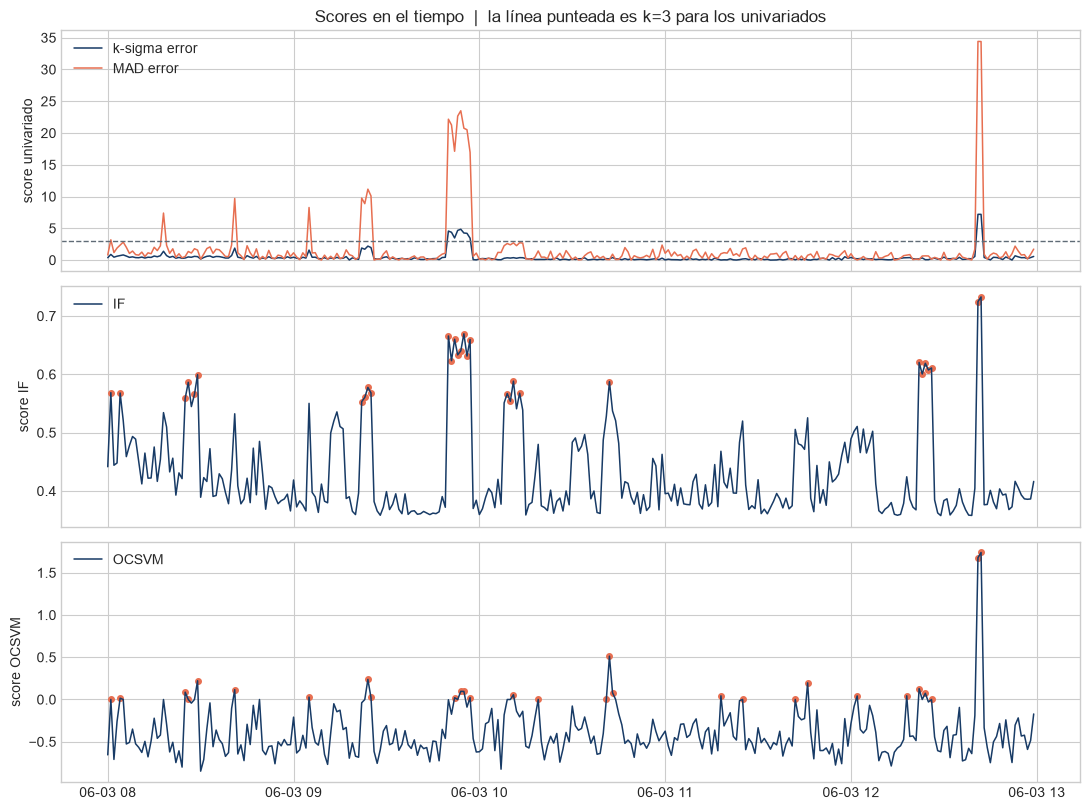

In [12]:
fig, axes = plt.subplots(3, 1, figsize=(11, 8.2), sharex=True)
axes[0].plot(data["timestamp"], data["score_ksigma_error"], color=BLUE, lw=1.1, label="k-sigma error")
axes[0].plot(data["timestamp"], data["score_mad_error"], color=ORANGE, lw=1.1, label="MAD error")
axes[0].axhline(3, color=GRAY, ls="--", lw=1)
axes[0].set_ylabel("score univariado")
axes[0].legend(loc="upper left")

axes[1].plot(data["timestamp"], data["score_if"], color=BLUE, lw=1.1, label="IF")
axes[1].scatter(data.loc[data["flag_if"], "timestamp"], data.loc[data["flag_if"], "score_if"], c=ORANGE, s=16)
axes[1].set_ylabel("score IF")
axes[1].legend(loc="upper left")

axes[2].plot(data["timestamp"], data["score_ocsvm"], color=BLUE, lw=1.1, label="OCSVM")
axes[2].scatter(data.loc[data["flag_ocsvm"], "timestamp"], data.loc[data["flag_ocsvm"], "score_ocsvm"], c=ORANGE, s=16)
axes[2].set_ylabel("score OCSVM")
axes[2].legend(loc="upper left")
axes[0].set_title("Scores en el tiempo  |  la línea punteada es k=3 para los univariados")
plt.tight_layout()
plt.show()


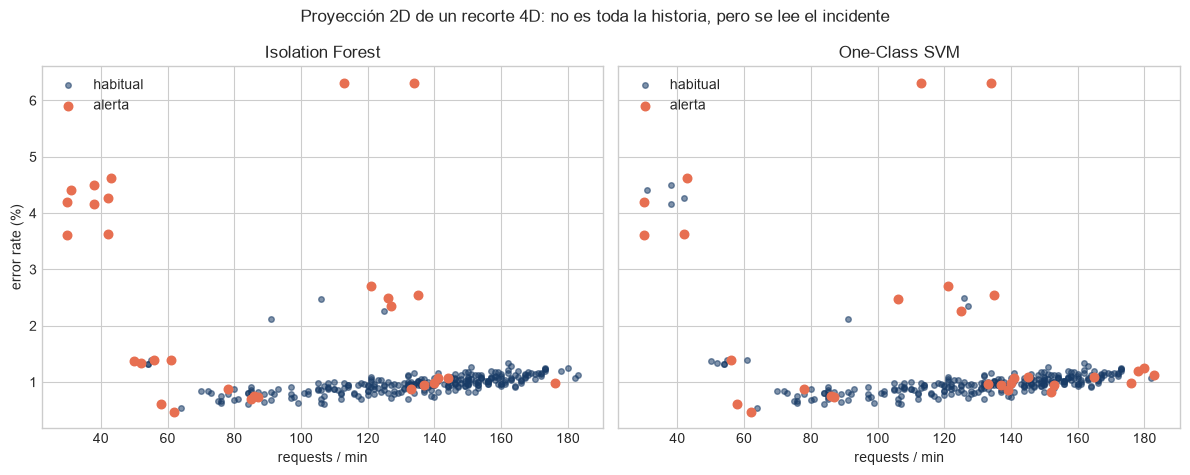

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharex=True, sharey=True)
for ax, flag_col, title in zip(axes, ("flag_if", "flag_ocsvm"), ("Isolation Forest", "One-Class SVM")):
    flags = data[flag_col]
    ax.scatter(data.loc[~flags, "requests"], 100 * data.loc[~flags, "error_rate"], c=BLUE, s=16, alpha=0.55, label="habitual")
    ax.scatter(data.loc[flags, "requests"], 100 * data.loc[flags, "error_rate"], c=ORANGE, s=38, label="alerta")
    ax.set_title(title)
    ax.set_xlabel("requests / min")
    ax.legend(loc="upper left")
axes[0].set_ylabel("error rate (%)")
plt.suptitle("Proyección 2D de un recorte 4D: no es toda la historia, pero se lee el incidente")
plt.tight_layout()
plt.show()


## 8b. Evidencia adicional para responder

Las secciones 3 a 8 quedan tal como las planteó la consigna. Lo que sigue no cambia ningún detector: solo saca de los mismos resultados la evidencia que piden las preguntas 3, 6, 7 y el exit ticket (primer minuto de detección, vectores concretos de falsos positivos y negativos, y sensibilidad a los hiperparámetros).

### 8b.1 Primer minuto de detección por modo

Para cada modo anómalo: cuántos minutos después de su inicio se enciende cada detector por primera vez (`+0` es el primer minuto del modo, `-` es que no lo detecta nunca).

In [14]:
rows = []
for kind_name in sorted(anomalous_kinds):
    m = data["kind"] == kind_name
    t0 = data.loc[m, "timestamp"].min()
    row = {"kind": kind_name, "inicio": t0.strftime("%H:%M"), "minutos": int(m.sum())}
    for name, col in FLAG_COLS.items():
        hits = data.loc[m & data[col], "timestamp"]
        row[name] = "-" if hits.empty else f"+{int((hits.min() - t0).total_seconds() // 60)}"
    rows.append(row)
first_hit = pd.DataFrame(rows).set_index("kind")
display(first_hit)

,inicio,minutos,k-sigma error,k-sigma lat,MAD error,MAD lat,Isolation Forest,One-Class SVM
kind,,,,,,,,
combo_sutil,10:08,7,-,-,-,-,+1,+3
cpu_latencia,12:22,5,-,-,-,+0,+0,+0
degradacion,11:50,18,-,-,-,+7,-,+12
incidente_5xx,09:50,8,+0,+0,+0,+0,+0,+2
latencia_silenciosa,10:40,6,-,-,-,+0,+2,+1
micro_burst,12:41,2,+0,+0,+0,+0,+0,+0
spike_error,08:18,3,-,-,+0,-,-,+23
timeouts,09:22,4,-,-,+0,+0,+0,+2


### 8b.2 La degradación minuto a minuto

La latencia sube en rampa durante 18 minutos. La tabla muestra, para cada minuto, la latencia, el score de cada detector y si se encendió.

In [15]:
deg_cols = ["timestamp", "requests", "latency_ms", "score_ksigma_lat", "score_mad_lat", "score_if", "score_ocsvm",
            "flag_ksigma_lat", "flag_mad_lat", "flag_if", "flag_ocsvm"]
deg = data.loc[data["kind"] == "degradacion", deg_cols].copy()
deg["timestamp"] = deg["timestamp"].dt.strftime("%H:%M")
display(deg.round(3).reset_index(drop=True))
print(f"Umbral de latencia equivalente: k-sigma {mu_lat + K * sig_lat:.1f} ms | MAD {med_lat + K * scale_lat:.1f} ms")

,timestamp,requests,latency_ms,score_ksigma_lat,score_mad_lat,score_if,score_ocsvm,flag_ksigma_lat,flag_mad_lat,flag_if,flag_ocsvm
0,11:50,140.0,109.374,0.028,0.874,0.379,-0.604,False,False,False,False
1,11:51,147.0,123.607,0.341,2.098,0.402,-0.604,False,False,False,False
2,11:52,153.0,112.565,0.054,1.148,0.375,-0.574,False,False,False,False
3,11:53,160.0,124.084,0.353,2.140,0.450,-0.644,False,False,False,False
4,11:54,144.0,123.257,0.332,2.068,0.415,-0.520,False,False,False,False
5,11:55,145.0,127.675,0.446,2.449,0.420,-0.776,False,False,False,False
6,11:56,132.0,133.625,0.601,2.961,0.429,-0.587,False,False,False,False
7,11:57,148.0,153.662,1.121,4.685,0.460,-0.760,False,True,False,False
8,11:58,140.0,159.684,1.277,5.203,0.483,-0.226,False,True,False,False
9,11:59,144.0,151.555,1.066,4.504,0.448,-0.553,False,True,False,False


Umbral de latencia equivalente: k-sigma 226.1 ms | MAD 134.1 ms


### 8b.3 Falsos positivos y falsos negativos

Primero el conteo por método y por modo. Después, los vectores $\mathbf x_t$ concretos que usa el exit ticket.

In [16]:
resumen = []
for name, col in FLAG_COLS.items():
    fp = data[data[col] & ~data["is_anomaly"]]
    fn = data[~data[col] & data["is_anomaly"]]
    resumen.append({
        "método": name,
        "FP": len(fp), "FP por kind": fp["kind"].value_counts().to_dict(),
        "FN": len(fn), "FN por kind": fn["kind"].value_counts().to_dict(),
    })
display(pd.DataFrame(resumen).set_index("método"))

cols_show = ["timestamp", "kind", *FEATURES, "score_mad_error", "score_mad_lat", "score_if", "score_ocsvm"]
print("Falsos positivos de Isolation Forest o One-Class SVM:")
fp_4d = data.loc[(data["flag_if"] | data["flag_ocsvm"]) & ~data["is_anomaly"], cols_show + ["flag_if", "flag_ocsvm"]]
display(fp_4d.assign(timestamp=fp_4d["timestamp"].dt.strftime("%H:%M")).round(4))

any_flag = data[list(FLAG_COLS.values())].any(axis=1)
print("Anomalías que ningún detector encendió:")
fn_all = data.loc[data["is_anomaly"] & ~any_flag, cols_show]
display(fn_all.assign(timestamp=fn_all["timestamp"].dt.strftime("%H:%M")).round(4))

,FP,FP por kind,FN,FN por kind
método,,,,
k-sigma error,0,{},43,"{'degradacion': 18, 'combo_sutil': 7, 'latenci..."
k-sigma lat,0,{},45,"{'degradacion': 18, 'combo_sutil': 7, 'latenci..."
MAD error,1,{'normal': 1},36,"{'degradacion': 18, 'combo_sutil': 7, 'latenci..."
MAD lat,0,{},17,"{'combo_sutil': 7, 'degradacion': 7, 'spike_er..."
Isolation Forest,6,"{'batch': 4, 'normal': 2}",29,"{'degradacion': 18, 'latencia_silenciosa': 5, ..."
One-Class SVM,11,"{'batch': 5, 'normal': 4, 'pico_carga': 2}",35,"{'degradacion': 17, 'combo_sutil': 6, 'inciden..."


Falsos positivos de Isolation Forest o One-Class SVM:


,timestamp,kind,requests,error_rate,latency_ms,cpu_pct,score_mad_error,score_mad_lat,score_if,score_ocsvm,flag_if,flag_ocsvm
1,08:01,normal,62.0,0.0048,77.8860,26.9502,3.1903,1.8362,0.5686,0.0005,True,True
4,08:04,normal,58.0,0.0060,76.6220,23.3712,2.3583,1.9450,0.5679,0.0148,True,True
25,08:25,batch,78.0,0.0088,81.5922,72.8978,0.5647,1.5172,0.5588,0.0867,True,True
26,08:26,batch,86.0,0.0076,73.6615,75.9183,1.3547,2.1998,0.5863,0.0001,True,True
28,08:28,batch,85.0,0.0069,77.6469,71.8857,1.7887,1.8568,0.5657,-0.0000,True,False
29,08:29,batch,87.0,0.0073,75.8911,82.0439,1.5746,2.0079,0.5996,0.2217,True,True
139,10:19,normal,178.0,0.0119,92.5528,48.9696,1.4324,0.5740,0.4799,0.0005,False,True
198,11:18,pico_carga,183.0,0.0113,104.4575,46.6767,0.9976,0.4505,0.4681,0.0432,False,True
205,11:25,pico_carga,180.0,0.0124,99.6555,53.1082,1.7512,0.0372,0.5199,0.0005,False,True
222,11:42,batch,145.0,0.0108,99.3225,79.2225,0.7157,0.0086,0.5056,0.0001,False,True


Anomalías que ningún detector encendió:


,timestamp,kind,requests,error_rate,latency_ms,cpu_pct,score_mad_error,score_mad_lat,score_if,score_ocsvm
128,10:08,combo_sutil,54.0,0.0132,119.1750,24.2911,2.2655,1.7171,0.5511,-0.1825
132,10:12,combo_sutil,54.0,0.0132,123.3490,28.1970,2.2680,2.0763,0.5409,-0.1383
134,10:14,combo_sutil,55.0,0.0139,123.6745,26.6693,2.6760,2.1043,0.5387,-0.1393
230,11:50,degradacion,140.0,0.0094,109.3736,36.2232,0.1766,0.8736,0.3792,-0.6044
231,11:51,degradacion,147.0,0.0092,123.6070,39.9377,0.3468,2.0985,0.4022,-0.6039
232,11:52,degradacion,153.0,0.0099,112.5647,39.2666,0.1441,1.1482,0.3754,-0.5739
233,11:53,degradacion,160.0,0.0112,124.0842,48.7268,0.9267,2.1395,0.4499,-0.6438
234,11:54,degradacion,144.0,0.0084,123.2568,39.8202,0.8357,2.0683,0.4155,-0.5196
235,11:55,degradacion,145.0,0.0107,127.6750,45.8038,0.6114,2.4485,0.4204,-0.7760
236,11:56,degradacion,132.0,0.0089,133.6252,38.6868,0.5222,2.9606,0.4289,-0.5869


### 8b.4 Sensibilidad de los univariados al umbral $k$ y regla combinada

La consigna fija $k=3$. Acá se ve qué pasa con otros valores, y con una regla simple que combina los dos MAD (alerta si error **o** latencia se salen).

In [17]:
def prf_flags(flags):
    p, r, f1, _ = precision_recall_fscore_support(data["is_anomaly"], flags, average="binary", zero_division=0)
    return p, r, f1

legit = data["kind"].isin(["batch", "pico_carga"])
rows = []
for k in (2.0, 2.5, 3.0, 3.5, 4.0):
    reglas = {
        "k-sigma error": data["score_ksigma_error"] > k,
        "k-sigma lat": data["score_ksigma_lat"] > k,
        "MAD error": data["score_mad_error"] > k,
        "MAD lat": data["score_mad_lat"] > k,
        "MAD error o lat": (data["score_mad_error"] > k) | (data["score_mad_lat"] > k),
    }
    for name, flags in reglas.items():
        p, r, f1 = prf_flags(flags)
        rows.append({"k": k, "regla": name, "alertas": int(flags.sum()), "precision": p, "recall": r, "f1": f1,
                     "FP en batch/pico": int((flags & legit).sum())})
sens_k = pd.DataFrame(rows)
display(sens_k.pivot(index="regla", columns="k", values="f1").round(3))
display(sens_k[sens_k["regla"] == "MAD error o lat"].round(3).reset_index(drop=True))

k,2.0,2.5,3.0,3.5,4.0
regla,,,,,
MAD error,0.539,0.553,0.479,0.486,0.486
MAD error o lat,0.857,0.889,0.839,0.848,0.848
MAD lat,0.882,0.822,0.809,0.809,0.809
k-sigma error,0.344,0.317,0.317,0.262,0.262
k-sigma lat,0.641,0.548,0.262,0.172,0.073


,k,regla,alertas,precision,recall,f1,FP en batch/pico
0,2.0,MAD error o lat,66,0.773,0.962,0.857,2
1,2.5,MAD error o lat,46,0.957,0.830,0.889,0
2,3.0,MAD error o lat,40,0.975,0.736,0.839,0
3,3.5,MAD error o lat,39,1.000,0.736,0.848,0
4,4.0,MAD error o lat,39,1.000,0.736,0.848,0


### 8b.5 Sensibilidad de Isolation Forest: `contamination`, `max_samples` y semilla

`contamination` fija cuántas alertas se emiten; `max_samples` ($\psi$) es el tamaño de la submuestra de cada árbol. Como el bosque es aleatorio, también se mide cuánto varía el F1 con la semilla.

In [18]:
rows = []
for cont in (0.05, 0.10, 0.15, 0.20):
    for ms in (64, 128, 256):
        model = IsolationForest(n_estimators=300, max_samples=ms, contamination=cont, random_state=42).fit(X_all)
        flags = model.predict(X_all) == -1
        p, r, f1 = prf_flags(flags)
        rows.append({"contamination": cont, "max_samples": ms, "alertas": int(flags.sum()),
                     "precision": p, "recall": r, "f1": f1, "FP en batch/pico": int((flags & legit).sum())})
sens_if = pd.DataFrame(rows)
display(sens_if.pivot(index="contamination", columns="max_samples", values="f1").round(3))

f1_seeds = []
for seed in range(20):
    model = IsolationForest(n_estimators=300, max_samples=min(256, len(data)), contamination=0.10, random_state=seed).fit(X_all)
    f1_seeds.append(prf_flags(model.predict(X_all) == -1)[2])
print(f"F1 de la configuración base con 20 semillas: media {np.mean(f1_seeds):.3f}, mín {np.min(f1_seeds):.3f}, máx {np.max(f1_seeds):.3f}")

max_samples,64,128,256
contamination,,,
0.05,0.412,0.412,0.441
0.10,0.627,0.627,0.578
0.15,0.653,0.673,0.673
0.20,0.637,0.655,0.690


F1 de la configuración base con 20 semillas: media 0.610, mín 0.554, máx 0.651


### 8b.6 Sensibilidad de One-Class SVM: `nu` y `gamma`

`nu` acota la fracción de puntos fuera de la frontera; `gamma` fija el ancho de cada campana RBF (`"scale"` es $1/(d\cdot\mathrm{Var}(X))$, acá $0.25$ porque las features están estandarizadas). Gamma chico da una frontera suave; gamma grande, una frontera que se pega a cada punto.

In [19]:
rows = []
for nu in (0.05, 0.10, 0.15, 0.20):
    for gamma in ("scale", 0.05, 0.1, 0.5, 1.0):
        model = OneClassSVM(kernel="rbf", nu=nu, gamma=gamma).fit(X_all)
        flags = model.predict(X_all) == -1
        p, r, f1 = prf_flags(flags)
        rows.append({"nu": nu, "gamma": str(gamma), "alertas": int(flags.sum()), "precision": p, "recall": r, "f1": f1,
                     "FP en batch/pico": int((flags & legit).sum()), "vectores soporte": int(model.support_.size)})
sens_svm = pd.DataFrame(rows)
display(sens_svm.pivot(index="nu", columns="gamma", values="f1").round(3))
display(sens_svm[sens_svm["nu"] == 0.10].round(3).reset_index(drop=True))

gamma,0.05,0.1,0.5,1.0,scale
nu,,,,,
0.05,0.290,0.290,0.453,0.359,0.319
0.10,0.429,0.500,0.410,0.410,0.439
0.15,0.510,0.580,0.626,0.536,0.592
0.20,0.559,0.609,0.595,0.613,0.637


,nu,gamma,alertas,precision,recall,f1,FP en batch/pico,vectores soporte
0,0.1,scale,29,0.621,0.340,0.439,7,39
1,0.1,0.05,31,0.581,0.340,0.429,7,34
2,0.1,0.1,31,0.677,0.396,0.500,5,37
3,0.1,0.5,25,0.640,0.302,0.410,5,41
4,0.1,1.0,30,0.567,0.321,0.410,5,58


> **Cuidado al leer 8b.4 a 8b.6.** Elegir hiperparámetros mirando el F1 usa las etiquetas `is_anomaly`, que en producción no existen. Estas tablas sirven para entender **cuán sensible** es cada detector, no para elegir la mejor configuración sobre los mismos 300 minutos: eso sería sobreajustar al dataset de evaluación.

### 8b.7 Cuánto infla la contaminación a cada estimador (pregunta 1)

Se recalculan $\hat\sigma$ y la escala MAD sacando de la muestra los modos que contaminan el error rate (`spike_error` y `micro_burst`), y después sacando todas las anomalías. Si un estimador es robusto, casi no se mueve.

In [20]:
def estimadores(serie):
    mu, sigma = k_sigma_fit(serie)
    med, mad, escala = mad_fit(serie)
    return {"mu": mu, "sigma": sigma, "umbral k-sigma": mu + K * sigma,
            "mediana": med, "escala MAD": escala, "umbral MAD": med + K * escala}

muestras = {
    "las 300 ventanas": data,
    "sin spike_error ni micro_burst": data[~data["kind"].isin(["spike_error", "micro_burst"])],
    "solo minutos no anómalos": data[~data["is_anomaly"]],
}
for col in ("error_rate", "latency_ms"):
    tabla = pd.DataFrame({nombre: estimadores(df[col]) for nombre, df in muestras.items()}).T
    print(col)
    display(tabla.round(4 if col == "error_rate" else 1))

error_rate


,mu,sigma,umbral k-sigma,mediana,escala MAD,umbral MAD
las 300 ventanas,0.0112,0.0072,0.0328,0.0097,0.0016,0.0144
sin spike_error ni micro_burst,0.0107,0.0057,0.0279,0.0097,0.0015,0.0142
solo minutos no anómalos,0.0095,0.0015,0.0141,0.0096,0.0015,0.0142


latency_ms


,mu,sigma,umbral k-sigma,mediana,escala MAD,umbral MAD
las 300 ventanas,110.5,38.5,226.1,99.2,11.6,134.1
sin spike_error ni micro_burst,109.6,36.3,218.4,99.3,11.5,133.8
solo minutos no anómalos,96.0,9.0,122.9,96.6,9.7,125.6


### 8b.8 Dónde ranquean los detectores 4D a `combo_sutil` (pregunta 3)

Percentil del score de cada minuto dentro de las 300 ventanas (100 es el minuto más anómalo según ese detector), y el máximo score univariado de cada minuto.

In [21]:
pct = data[["score_if", "score_ocsvm"]].rank(pct=True) * 100
combo = data.loc[data["kind"] == "combo_sutil", ["timestamp", *FEATURES, "score_ksigma_error", "score_mad_error", "score_mad_lat",
                                                  "flag_if", "flag_ocsvm"]].copy()
combo["max score MAD"] = combo[["score_mad_error", "score_mad_lat"]].max(axis=1)
combo["percentil IF"] = pct.loc[combo.index, "score_if"]
combo["percentil OCSVM"] = pct.loc[combo.index, "score_ocsvm"]
combo["timestamp"] = combo["timestamp"].dt.strftime("%H:%M")
display(combo.round(3).reset_index(drop=True))

mediana_pct = pd.DataFrame({
    "percentil mediano IF": pct["score_if"].groupby(data["kind"]).median(),
    "percentil mediano OCSVM": pct["score_ocsvm"].groupby(data["kind"]).median(),
}).sort_values("percentil mediano IF", ascending=False)
display(mediana_pct.round(1))

,timestamp,requests,error_rate,latency_ms,cpu_pct,score_ksigma_error,score_mad_error,score_mad_lat,flag_if,flag_ocsvm,max score MAD,percentil IF,percentil OCSVM
0,10:08,54.0,0.013,119.175,24.291,0.284,2.266,1.717,False,False,2.266,90.000,79.000
1,10:09,50.0,0.014,118.598,23.178,0.358,2.608,1.667,True,False,2.608,92.000,89.000
2,10:10,52.0,0.013,126.347,28.047,0.313,2.400,2.334,True,False,2.400,90.667,89.667
3,10:11,56.0,0.014,119.558,19.454,0.380,2.710,1.750,True,True,2.710,94.667,95.667
4,10:12,54.0,0.013,123.349,28.197,0.285,2.268,2.076,False,False,2.268,89.000,81.333
5,10:13,61.0,0.014,127.157,25.041,0.384,2.727,2.404,True,False,2.727,92.333,77.667
6,10:14,55.0,0.014,123.674,26.669,0.373,2.676,2.104,False,False,2.676,88.667,81.000


,percentil mediano IF,percentil mediano OCSVM
kind,,
micro_burst,99.8,99.8
incidente_5xx,98.2,91.7
cpu_latencia,96.0,91.0
timeouts,92.2,90.7
combo_sutil,90.7,81.3
spike_error,87.7,94.3
latencia_silenciosa,86.5,89.7
batch,83.7,81.2
degradacion,73.3,47.5


### 8b.9 Un minuto de `pico_carga` contra uno de `incidente_5xx` (pregunta 4)

Para cada minuto: su posición en el plano requests contra error rate respecto de la nube normal (error esperado según la relación lineal del generador, $0.0035 + 0.000045\,N_t$) y las flags 4D.

In [22]:
normal = data[data["kind"] == "normal"]
print(f"Nube normal: requests entre {normal.requests.min():.0f} y {normal.requests.max():.0f}, "
      f"error rate entre {normal.error_rate.min():.4f} y {normal.error_rate.max():.4f}")
cols_q4 = ["timestamp", "kind", "requests", "error_rate", "latency_ms", "cpu_pct", "score_if", "score_ocsvm", "flag_if", "flag_ocsvm"]
q4 = data.loc[data["kind"].isin(["pico_carga", "incidente_5xx"]), cols_q4].copy()
q4["error esperado"] = 0.0035 + 0.000045 * q4["requests"]
q4["error / esperado"] = q4["error_rate"] / q4["error esperado"]
q4["timestamp"] = q4["timestamp"].dt.strftime("%H:%M")
display(q4.round(4).reset_index(drop=True))

Nube normal: requests entre 58 y 178, error rate entre 0.0048 y 0.0134


,timestamp,kind,requests,error_rate,latency_ms,cpu_pct,score_if,score_ocsvm,flag_if,flag_ocsvm,error esperado,error / esperado
0,09:50,incidente_5xx,31.0,0.0442,249.3325,33.9591,0.6658,-0.0027,True,False,0.0049,9.0225
1,09:51,incidente_5xx,42.0,0.0428,226.5358,34.4379,0.6234,-0.1745,True,False,0.0054,7.9317
2,09:52,incidente_5xx,42.0,0.0363,253.9382,39.5850,0.6601,0.0211,True,True,0.0054,6.7381
3,09:53,incidente_5xx,38.0,0.0449,228.6530,39.5630,0.6334,-0.0001,True,False,0.0052,8.6222
4,09:54,incidente_5xx,43.0,0.0462,238.2539,38.2677,0.6403,0.0966,True,True,0.0054,8.5052
5,09:55,incidente_5xx,30.0,0.0420,223.5171,30.2513,0.6695,0.0954,True,True,0.0048,8.6509
6,09:56,incidente_5xx,38.0,0.0416,218.0294,35.1313,0.6313,-0.0903,True,False,0.0052,7.9826
7,09:57,incidente_5xx,30.0,0.0361,248.7454,38.5378,0.6597,0.0229,True,True,0.0048,7.4362
8,11:18,pico_carga,183.0,0.0113,104.4575,46.6767,0.4681,0.0432,False,True,0.0117,0.9597
9,11:19,pico_carga,172.0,0.0115,103.0362,47.8371,0.4148,-0.3131,False,False,0.0112,1.0252


### 8b.10 Exit ticket: probar los cambios propuestos

Dos cambios, ninguno usa `kind` ni `is_anomaly` para entrenar:

1. **Residuo del error rate respecto de la carga.** Se ajusta una recta robusta (Huber) de `error_rate` contra `requests` sobre las 300 ventanas y se mira el residuo con MAD. Pregunta nueva: ¿el error es raro *para este nivel de tráfico*? Apunta al falso negativo de `combo_sutil`.
2. **Sacar `cpu_pct` del detector 4D.** El `batch` es legítimo y solo se sale de la nube por CPU. Sin esa feature, la CPU queda para una alerta de saturación aparte. Apunta al falso positivo del `batch`.

Se compara contra la configuración base con los mismos hiperparámetros.

In [23]:
from sklearn.linear_model import HuberRegressor

huber = HuberRegressor().fit(data[["requests"]], data["error_rate"])
data["error_resid"] = data["error_rate"] - huber.predict(data[["requests"]])
med_res, mad_res, scale_res = mad_fit(data["error_resid"])
data["score_mad_resid"] = mad_score(data["error_resid"], med_res, scale_res)
data["flag_mad_resid"] = data["score_mad_resid"] > K
print(f"Recta robusta: error = {huber.intercept_:.4f} + {huber.coef_[0]:.6f} * requests  (generador: 0.0035 + 0.000045 * requests)")

FEAT_3D = ["requests", "error_rate", "latency_ms"]
X_3d = StandardScaler().fit_transform(data[FEAT_3D])
data["flag_if_3d"] = IsolationForest(n_estimators=300, max_samples=min(256, len(data)), contamination=0.10,
                                     random_state=42).fit(X_3d).predict(X_3d) == -1
data["flag_ocsvm_3d"] = OneClassSVM(kernel="rbf", nu=0.10, gamma="scale").fit(X_3d).predict(X_3d) == -1
data["flag_mad_resid_o_lat"] = data["flag_mad_resid"] | data["flag_mad_lat"]

VARIANTES = {
    "MAD error (base)": "flag_mad_error",
    "MAD residuo": "flag_mad_resid",
    "MAD residuo o lat": "flag_mad_resid_o_lat",
    "IF 4D (base)": "flag_if",
    "IF sin CPU": "flag_if_3d",
    "OCSVM 4D (base)": "flag_ocsvm",
    "OCSVM sin CPU": "flag_ocsvm_3d",
}
por_kind = data.groupby("kind")[list(VARIANTES.values())].sum().astype(int)
por_kind.columns = list(VARIANTES)
por_kind.insert(0, "n", data.groupby("kind").size())
display(por_kind)
display(pd.DataFrame({name: prf(col) for name, col in VARIANTES.items()}).T.round(3))

Recta robusta: error = 0.0056 + 0.000030 * requests  (generador: 0.0035 + 0.000045 * requests)


,n,MAD error (base),MAD residuo,MAD residuo o lat,IF 4D (base),IF sin CPU,OCSVM 4D (base),OCSVM sin CPU
kind,,,,,,,,
batch,20,0,0,0,4,0,5,0
combo_sutil,7,0,7,7,4,7,1,2
cpu_latencia,5,0,0,5,5,0,3,1
degradacion,18,0,0,11,0,0,1,1
incidente_5xx,8,8,8,8,8,8,4,5
latencia_silenciosa,6,0,0,6,1,3,3,2
micro_burst,2,2,2,2,2,2,2,2
normal,219,1,0,0,2,3,4,5
pico_carga,8,0,0,0,0,0,2,3


,precision,recall,f1,alertas
MAD error (base),0.944,0.321,0.479,18.0
MAD residuo,1.000,0.453,0.623,24.0
MAD residuo o lat,1.000,0.868,0.929,46.0
IF 4D (base),0.800,0.453,0.578,30.0
IF sin CPU,0.900,0.509,0.651,30.0
OCSVM 4D (base),0.621,0.340,0.439,29.0
OCSVM sin CPU,0.704,0.358,0.475,27.0


## 9. Preguntas (para entregar / discutir)

Respondan con evidencia de las tablas y gráficos, no con la definición del método.

1. Comparen $\sigma$ de k-sigma contra la escala MAD en `error_rate`. ¿Qué le hicieron los `spike_error` y el `micro_burst` a cada una? ¿Se ve el mismo efecto en `latency_ms`?
2. ¿Qué kinds prende k-sigma sobre error rate y **no** prende sobre latencia? ¿Y al revés? ¿Por qué `latencia_silenciosa` es el ejemplo canónico?
3. ¿Algún minuto de `combo_sutil` cruza $k=3$ en un eje solo? Si no, ¿lo ranquean IF u OCSVM cerca de la cima aunque la flag no se encienda?
4. Tomen un minuto de `pico_carga` y uno de `incidente_5xx`. En el plano requests–error rate, ¿quién está al borde de la nube y quién afuera? ¿Coinciden las flags 4D con esa geometría?
5. El `batch` es legítimo. ¿Qué detector lo trata como anomalía y por qué un modo raro (aunque operativo) se parece a un outlier?
6. En `degradacion`, ¿cuál es el primer minuto que cada método enciende? ¿Qué le falta a un detector i.i.d. minuto a minuto?
7. `nu=0.10` y `contamination=0.10` recortan más o menos el mismo presupuesto de alertas. ¿Obtienen el mismo F1? Si no, ¿dónde se pelean?

### Exit ticket

Elijan **un** falso negativo y **un** falso positivo de cualquier método. Para cada uno: el vector $\mathbf x_t$, qué pregunta hacía el detector, y qué cambiarían (feature, umbral o ventana de train) sin romper el resto.


## 10. Respuestas

Cada número sale de las tablas de las secciones 4 a 8 y 8b; entre paréntesis, la tabla de donde sale.

**1. σ de k-sigma contra la escala MAD.** En `error_rate`, k-sigma estima $\hat\sigma = 0{,}0072$ sobre las 300 ventanas y MAD una escala de $0{,}0016$: 4,5 veces más angosta (sección 5). Los tres `spike_error` (0,021 a 0,025) y los dos minutos de `micro_burst` (0,055 a 0,070) explican parte de esa diferencia: sin ellos $\hat\sigma$ baja a 0,0057 y el umbral k-sigma de 0,0328 a 0,0279. El resto lo ponen los incidentes: sin ninguna anomalía $\hat\sigma$ sería 0,0015. La escala MAD casi no se mueve en ningún caso (de 0,0016 a 0,0015), porque la mediana de los desvíos no mira las colas (8b.7). La consecuencia se ve en las flags: el umbral k-sigma inflado queda por encima de los propios spikes y de los `timeouts` (0,023 a 0,028), que k-sigma no detecta (0 de 3 y 0 de 4), mientras que MAD, con umbral 0,0144, los detecta todos (3 de 3 y 4 de 4). En `latency_ms` pasa lo mismo, pero con otros culpables: los `spike_error` no tocan la latencia y el `micro_burst` apenas la mueve ($\hat\sigma$ pasa de 38,5 a 36,3 ms sin ellos). Lo que la infla son los modos de latencia (incidente, timeouts, latencia silenciosa, CPU con latencia y degradación): sin anomalías $\hat\sigma$ sería 9,0 ms. Resultado: umbral k-sigma de 226,1 ms contra 134,1 ms de MAD. La consigna fija $k=3$ para los dos métodos; con un umbral de 3,5 para MAD, la conclusión no cambia: MAD sobre latencia da el mismo F1 de 0,809 y MAD sobre error pasa de 0,479 a 0,486 (8b.4).

**2. Qué ve k-sigma en un eje y no en el otro.** Sobre error rate, k-sigma enciende `incidente_5xx` (8 de 8) y `micro_burst` (2 de 2). Sobre latencia enciende los mismos modos, pero solo 6 de los 8 minutos del incidente: el de las 09:55 (223,5 ms) y el de las 09:56 (218,0 ms) quedan debajo del umbral inflado de 226,1 ms (sección 8). Al revés no hay ningún caso: lo que k-sigma ve en latencia también lo ve en error. Los modos que solo rompen la latencia (`latencia_silenciosa`, `cpu_latencia`, `degradacion`) quedan en cero para los dos k-sigma. `latencia_silenciosa` es el ejemplo canónico porque es el caso puro: requests, error rate y CPU siguen normales, así que un detector sobre error rate es ciego por construcción, y el único eje que se rompe (195 a 230 ms) queda bajo el umbral de 226 ms que la contaminación le infló a k-sigma (0 de 6, score mediano 2,68). MAD sobre el mismo eje, con umbral 134 ms, lo detecta entero desde el primer minuto (6 de 6, score mediano 9,85; 8b.1).

**3. `combo_sutil`.** Ningún minuto cruza $k=3$ en un eje solo: el máximo score MAD de cada minuto va de 2,27 a 2,73, y en k-sigma no pasa de 0,38 (8b.8). Los detectores 4D sí lo ranquean alto, aunque en el borde. Isolation Forest pone sus 7 minutos entre los percentiles 88,7 y 94,7 de las 300 ventanas (mediana 90,7: el quinto modo más anómalo, detrás de `micro_burst`, `incidente_5xx`, `cpu_latencia` y `timeouts`), y como `contamination=0.10` corta justo en el percentil 90, marca 4 de 7. One-Class SVM lo ranquea más abajo (percentil mediano 81,3) y marca 1 de 7. Lo delata la combinación (poco tráfico con error alto), no un eje.

**4. Pico de carga contra incidente en el plano requests y error rate.** El `pico_carga` está en el borde de la nube: a las 11:18 tiene 183 requests (la nube normal llega a 178) y un error de 0,0113, que es 0,96 veces el esperado para esa carga. El `incidente_5xx` está afuera: a las 09:53 tiene 38 requests y un error de 0,0449, 8,6 veces el esperado para ese tráfico y más del triple del máximo error normal (0,0134) (8b.9). Isolation Forest respeta esa geometría: 0 de 8 en el pico y 8 de 8 en el incidente. One-Class SVM no: marca 2 minutos del pico (los de 183 y 180 requests, el extremo de la nube) y solo 4 de los 8 del incidente. La explicación es que entrena sobre datos contaminados: los 8 minutos del incidente forman un grupo compacto, y la frontera RBF los termina envolviendo como si fueran una región normal más (scores cerca de 0).

**5. El `batch`.** Los univariados no lo ven, porque miran error y latencia, y el batch los deja normales. Lo tratan como anomalía Isolation Forest (4 de 20) y One-Class SVM (5 de 20), que son los que miran la CPU: el batch tiene entre 70 y 84% de CPU con tráfico normal, cuando la relación habitual daría entre 29 y 44% (8b.3). En 4D es un punto fuera del manifold, y un detector no supervisado mide rareza, no intención: un modo raro y legítimo es, para él, igual que un outlier. Los cuatro falsos positivos de IF son del batch de las 08:25, con tráfico bajo (78 a 87 requests), donde el desvío de CPU respecto de lo esperado es mayor. Saber que el batch es legítimo requiere contexto que el vector no tiene, como el horario del job (ver el exit ticket).

**6. Primer minuto en `degradacion`.** La degradación arranca a las 11:50 (8b.1 y 8b.2). MAD sobre latencia se enciende a los 7 minutos (11:57, con 153,7 ms sobre su umbral de 134 ms) y desde ahí marca 11 de los 18 minutos. One-Class SVM se enciende a los 12 minutos y solo en ese minuto (12:02). Isolation Forest y los dos k-sigma no se encienden nunca: k-sigma necesita 226 ms y la rampa llega a 208,7. Los primeros minutos (109 a 134 ms) caen dentro del ruido normal ($\hat\sigma \approx 9$ ms sin anomalías): uno por uno son indistinguibles de un minuto normal. Lo que le falta a un detector i.i.d. es memoria: juzga cada minuto solo y no ve que la latencia viene subiendo hace varios minutos. Para eso hacen falta features de ventana (media móvil, pendiente, EWMA o CUSUM) o comparar contra un pronóstico, que es lo que aporta el análisis de series temporales.

**7. Mismo presupuesto, distinto F1.** Las alertas son casi las mismas (30 de IF, 29 de OCSVM; `nu` es una cota, no una cantidad exacta), pero el F1 no: 0,578 contra 0,439 (sección 8). Se pelean en dos lugares. En falsos positivos: OCSVM gasta 11 alertas en minutos legítimos (5 de batch, 4 normales y 2 del pico de carga) y IF 6 (4 de batch y 2 normales). En los modos que detecta: IF gana en `incidente_5xx` (8 contra 4), `combo_sutil` (4 contra 1) y `timeouts` (4 contra 2); OCSVM gana en `spike_error` (2 contra 0), `latencia_silenciosa` (3 contra 1) y `degradacion` (1 contra 0). La diferencia no es ruido de la semilla: con 20 semillas, el F1 de IF va de 0,554 a 0,651 (8b.5). Además, OCSVM es mucho más sensible a sus hiperparámetros: en la grilla de `nu` y `gamma` su F1 va de 0,29 a 0,64 (8b.6), mientras que el de IF va de 0,41 a 0,69, casi todo por `contamination`, es decir, por cuántas alertas emite.

**Conclusión.** El mejor detector individual es el más simple: MAD sobre latencia (F1 0,809, precisión 1,0). Los modelos 4D no le ganan, pero ven lo que ningún eje solo ve (`combo_sutil`). Combinar MAD sobre error o sobre latencia lleva el F1 a 0,839 (8b.4), y con el residuo del exit ticket, a 0,929 (8b.10). Esas comparaciones usan las etiquetas, así que sirven para entender el comportamiento de cada detector, no para elegir hiperparámetros sobre estos mismos 300 minutos.

### Exit ticket

**Falso negativo: `combo_sutil` a las 10:14**, con $\mathbf x_t$ = (55 requests, error 0,0139, 123,7 ms, CPU 26,7%). MAD preguntaba si algún eje estaba lejos de la mediana: no (máximo 2,68, debajo de 3). Isolation Forest preguntaba si el punto se aislaba rápido: casi (percentil 88,7, apenas debajo del corte del 90). Ninguno pregunta lo que importa acá: si el error es raro *para ese nivel de tráfico*. Cambio: una feature de residuo, el error rate menos lo que predice una recta robusta (Huber) de error contra requests, ajustada sin etiquetas, con MAD encima. En 8b.10 detecta los 7 minutos de `combo_sutil` sin ningún falso positivo nuevo (0 en normal, batch y pico de carga), y combinada con MAD sobre latencia da F1 0,929.

**Falso positivo: `batch` a las 08:25 en One-Class SVM**, con $\mathbf x_t$ = (78 requests, error 0,0088, 81,6 ms, CPU 72,9%). La pregunta del detector, si el punto queda fuera del volumen normal, se responde bien: queda afuera, solo por la CPU. Cambio: sacar `cpu_pct` del detector 4D y dejar la CPU para una alerta de saturación que además exija latencia alta. En 8b.10 los falsos positivos en batch bajan a 0 en IF y en OCSVM. El costo es que IF sin CPU deja de ver `cpu_latencia` (de 5 a 0), que igual queda cubierto por MAD sobre latencia (5 de 5): el cambio funciona en combinación con el univariado, no solo.

Las dos propuestas se diseñaron mirando los resultados de este mismo dataset; antes de usarlas en producción habría que validarlas con datos nuevos.